In [1]:
import os
import requests
import zipfile
from zipfile import ZipFile, BadZipFile
import numpy as np
import pandas as pd
from PIL import Image

from dataclasses import dataclass
from typing import List, Tuple, Union

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import functional as F

import matplotlib.pyplot as plt

import torch.nn as nn
import torch.nn.functional as F_nn   # note: avoid clashing with your transforms F import — see below
from torchvision.transforms import functional as TF   # for image transforms
import torch.nn.functional as F                         # for model activations

from torchvision import models
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

from torch.utils.tensorboard import SummaryWriter

from tqdm import tqdm

2026-10-23 17:21:39.746024: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792776099.915436      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792776099.960867      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792776100.339328      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792776100.339367      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792776100.339370      23 computation_placer.cc:177] computation placer alr

In [2]:
import random

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [3]:
!pip install tqdm scikit-learn

In [4]:
data_root = "/kaggle/input/open-cv-py-torch-project-2-classification-round-4"
img_dir = os.path.join(data_root, "images", "images")

# sanity checks (safe to remove later)
print(os.listdir(data_root))
print(os.listdir(img_dir)[:5])


class KenyanFood13Dataset(Dataset):
    """
    Custom dataset class for the Kenyan Food 13 classification dataset.
    Takes a dataframe (already split into train or val), an image directory,
    and a class-to-index mapping (so string labels become integers).
    """

    def __init__(self, df, img_dir, class_to_idx, image_shape=None, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.class_to_idx = class_to_idx
        self.image_shape = image_shape
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_id = str(self.df.loc[idx, 'id'])
        class_name = self.df.loc[idx, 'class']
        label = self.class_to_idx[class_name]

        image = Image.open(os.path.join(self.img_dir, f"{img_id}.jpg")).convert("RGB")

        if self.image_shape is not None:
            image = F.resize(image, self.image_shape)

        if self.transform is not None:
            image = self.transform(image)

        return image, label




['sample_submission.csv', 'images', 'train.csv', 'test.csv']
['18286077912045734721.jpg', '10404026255145922708.jpg', '10287249802413271822.jpg', '18355411125526475604.jpg', '10536300270659742242.jpg']


In [5]:
from torchvision.models import ResNet50_Weights

def get_data(data_root, img_dir, batch_size, num_workers=1,
             img_height=224, img_width=224, val_split=0.2):

    full_df = pd.read_csv(os.path.join(data_root, 'train.csv'))

    classes = sorted(full_df['class'].unique())
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}

    full_df = full_df.sample(frac=1, random_state=42).reset_index(drop=True)
    val_size = int(len(full_df) * val_split)
    val_df = full_df[:val_size]
    train_df = full_df[val_size:]

    imagenet_mean = [0.485, 0.456, 0.406]
    imagenet_std  = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((img_height, img_width)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.RandomResizedCrop((img_height, img_width), scale=(0.8, 1.0)),
        transforms.ToTensor(),
        transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
        transforms.RandomErasing(p=0.3)
    ])

    val_transform = transforms.Compose([
        transforms.Resize((img_height, img_width)),
        transforms.ToTensor(),
        transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
    ])

    train_dataset = KenyanFood13Dataset(train_df, img_dir, class_to_idx, transform=train_transform)
    val_dataset = KenyanFood13Dataset(val_df, img_dir, class_to_idx, transform=val_transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    return train_loader, val_loader, class_to_idx



train_loader, val_loader, class_to_idx = get_data(data_root, img_dir, batch_size=32)

print(f"Number of classes: {len(class_to_idx)}")
print(f"Class mapping: {class_to_idx}")
print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

Number of classes: 13
Class mapping: {'bhaji': 0, 'chapati': 1, 'githeri': 2, 'kachumbari': 3, 'kukuchoma': 4, 'mandazi': 5, 'masalachips': 6, 'matoke': 7, 'mukimo': 8, 'nyamachoma': 9, 'pilau': 10, 'sukumawiki': 11, 'ugali': 12}
Train batches: 164, Val batches: 41


In [6]:
# data_root = r"/kaggle/input/open-cv-py-torch-project-2-classification-round-4/images"
# print(os.listdir(os.path.join(data_root, "images"))[:5])

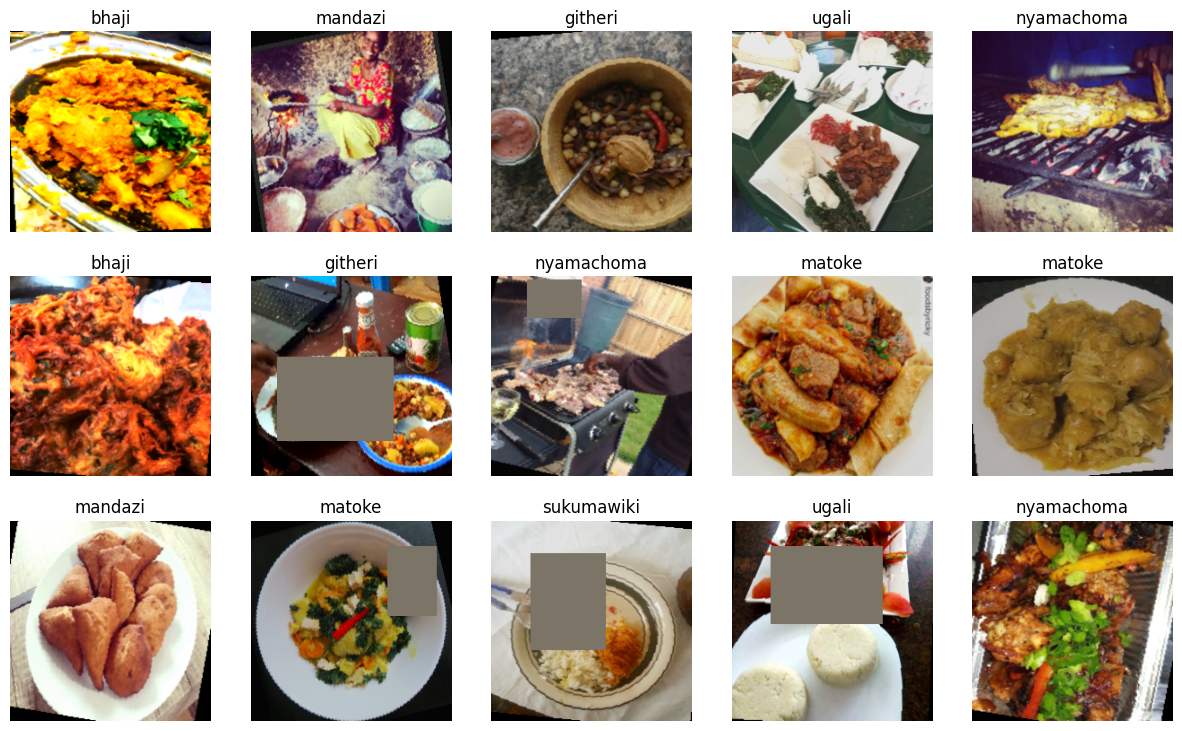

In [7]:
def denormalize(tensor, mean, std):
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return tensor * std + mean

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

plt.rcParams["figure.figsize"] = (15, 9)
idx_to_class = {v: k for k, v in class_to_idx.items()}

for images, labels in train_loader:
    for i in range(min(15, len(labels))):
        plt.subplot(3, 5, i+1)
        img_tensor = denormalize(images[i], imagenet_mean, imagenet_std).clamp(0, 1)
        img = TF.to_pil_image(img_tensor)
        plt.imshow(img)
        plt.gca().set_title(idx_to_class[labels[i].item()])
        plt.axis('off')
    plt.show()
    break

In [8]:
# detele later

train_csv = pd.read_csv(os.path.join(data_root, 'train.csv'))
test_csv = pd.read_csv(os.path.join(data_root, 'test.csv'))

print(f"train.csv rows: {len(train_csv)}")
print(f"test.csv rows: {len(test_csv)}")
print(f"total images in folder: {len(os.listdir(img_dir))}")
print(f"train + test: {len(train_csv) + len(test_csv)}")

train.csv rows: 6536
test.csv rows: 1638
total images in folder: 8174
train + test: 8174


In [9]:
@dataclass(frozen=True)
class DatasetConfig:
    NUM_CLASSES: int = 13
    IMG_HEIGHT:  int = 224
    IMG_WIDTH:   int = 224
    BATCH_SIZE:  int = 32
    NUM_WORKERS: int = 2
    DATA_ROOT:  str  = "/kaggle/input/open-cv-py-torch-project-2-classification-round-4"


@dataclass(frozen=True)
class TrainingConfig:
    EPOCHS:         int   = 20
    LEARNING_RATE:  float = 5e-5
    LOG_DIR:        str   = "FT-LOGS-KenyanFood13"
    CHECKPOINT_DIR: str   = "FT_KenyanFood13_CHECKPOINTS"
    TEST_INTERVAL:  int   = 1

In [10]:
from sklearn.metrics import f1_score

In [11]:
def calculate_accuracy(outputs, labels):
    """
    outputs: model predictions (raw scores) for a batch
    labels: true labels for that batch
    Returns accuracy as a fraction (0 to 1)
    """
    _, predicted = torch.max(outputs, 1)
    correct = (predicted == labels).sum().item()
    total = labels.size(0)
    return correct / total

def calculate_f1(outputs, labels):
    """
    outputs: model predictions (raw scores) for a batch
    labels: true labels for that batch
    Returns macro F1-score
    """
    _, predicted = torch.max(outputs, 1)
    predicted = predicted.cpu().numpy()
    labels = labels.cpu().numpy()
    return f1_score(labels, predicted, average='macro', zero_division=0)

In [12]:
class MeanMetric:
    """
    Keeps a running average of any number (loss, accuracy, f1...)
    across multiple batches in an epoch.
    """

    def __init__(self):
        self.total = 0.0
        self.count = 0

    def update(self, value, n=1):
        self.total += value * n
        self.count += n

    def compute(self):
        if self.count == 0:
            return 0.0
        return self.total / self.count

    def reset(self):
        self.total = 0.0
        self.count = 0

In [13]:
from tqdm import tqdm

In [14]:
def train(
    DEVICE,
    train_config: TrainingConfig,
    dataset_config: DatasetConfig,
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    train_loader: torch.utils.data.DataLoader,
    epoch_idx: int,
    total_epochs: int
) -> Tuple[float, float]:

    model.train()

    loss_metric = MeanMetric()
    acc_metric = MeanMetric()

    status = f"Train:\tEpoch: {epoch_idx}/{total_epochs}"

    prog_bar = tqdm(train_loader, bar_format='{l_bar}{bar:10}{r_bar}{bar:-10b}')
    prog_bar.set_description(status)

    for data, target in prog_bar:

        data, target = data.to(DEVICE), target.to(DEVICE)

        optimizer.zero_grad()

        output = model(data)
        criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

        loss = criterion(output, target)

        loss.backward()
        optimizer.step()

        # accuracy for this batch
        batch_acc = calculate_accuracy(output, target)

        # update running averages, weighted by batch size
        loss_metric.update(loss.item(), n=data.shape[0])
        acc_metric.update(batch_acc, n=data.shape[0])

        step_status = status + f"\tLoss: {loss_metric.compute():.4f}, Acc: {acc_metric.compute():.4f}"
        prog_bar.set_description(step_status)

    epoch_loss = loss_metric.compute()
    epoch_acc = acc_metric.compute()

    prog_bar.close()

    return epoch_loss, epoch_acc

In [15]:
def validate(
    DEVICE,
    dataset_config: DatasetConfig,
    model: nn.Module,
    val_loader: torch.utils.data.DataLoader,
    epoch_idx: int,
    total_epochs: int
) -> Tuple[float, float, float]:

    model.eval()

    loss_metric = MeanMetric()
    acc_metric = MeanMetric()
    f1_metric = MeanMetric()

    status = f"Valid:\tEpoch: {epoch_idx}/{total_epochs}"

    prog_bar = tqdm(val_loader, bar_format='{l_bar}{bar:10}{r_bar}{bar:-10b}')
    prog_bar.set_description(status)

    with torch.no_grad():
        for data, target in prog_bar:

            data, target = data.to(DEVICE), target.to(DEVICE)

            output = model(data)
            criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
            loss = criterion(output, target)

            batch_acc = calculate_accuracy(output, target)
            batch_f1 = calculate_f1(output, target)

            loss_metric.update(loss.item(), n=data.shape[0])
            acc_metric.update(batch_acc, n=data.shape[0])
            f1_metric.update(batch_f1, n=data.shape[0])

            step_status = status + f"\tLoss: {loss_metric.compute():.4f}, Acc: {acc_metric.compute():.4f}, F1: {f1_metric.compute():.4f}"
            prog_bar.set_description(step_status)

    epoch_loss = loss_metric.compute()
    epoch_acc = acc_metric.compute()
    epoch_f1 = f1_metric.compute()

    prog_bar.close()

    return epoch_loss, epoch_acc, epoch_f1

In [16]:
from torchvision.models import resnet50


def get_resnet_50(num_classes, dropout=0.5):
    model = resnet50(weights="DEFAULT")
    for p in model.parameters():
        p.requires_grad = False
    for p in model.layer3.parameters():
        p.requires_grad = True
    for p in model.layer4.parameters():
        p.requires_grad = True
    num_features = model.fc.in_features
    model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(num_features, num_classes))
    return model

In [17]:
import os
import random
import numpy as np
import torch
from torch.utils.tensorboard import SummaryWriter


def set_seed(seed=42):
    """
    Sets random seed across all libraries used, for reproducible results.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device():
    """
    Returns GPU device if available, otherwise CPU.
    """
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def save_checkpoint(model, optimizer, epoch, checkpoint_dir, filename="best_model.pth"):
    """
    Saves model + optimizer state, so training can be resumed
    or the best model can be reloaded later for evaluation.
    """
    os.makedirs(checkpoint_dir, exist_ok=True)
    checkpoint_path = os.path.join(checkpoint_dir, filename)

    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
    }, checkpoint_path)

    print(f"Checkpoint saved: {checkpoint_path}")


def load_checkpoint(model, optimizer, checkpoint_path, device):
    """
    Loads a saved checkpoint back into the model and optimizer.
    """
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    epoch = checkpoint['epoch']

    print(f"Checkpoint loaded: {checkpoint_path} (epoch {epoch})")
    return model, optimizer, epoch


def get_writer(log_dir):
    """
    Creates a TensorBoard SummaryWriter for logging training/validation metrics.
    """
    os.makedirs(log_dir, exist_ok=True)
    return SummaryWriter(log_dir=log_dir)

In [18]:
# import time
# import copy


# def main(
#     DEVICE: torch.device,
#     model: nn.Module,
#     optimizer: Union[optim.SGD, optim.Adam],
#     ckpt_dir: str,
#     summary_writer,
#     data_config: DatasetConfig,
#     train_config: TrainingConfig
# ) -> dict:

#     # data loaders
#     train_loader, val_loader, class_to_idx = get_data(
#         data_root=data_config.DATA_ROOT,
#         img_dir=os.path.join(data_config.DATA_ROOT, "images", "images"),
#         batch_size=data_config.BATCH_SIZE,
#         num_workers=data_config.NUM_WORKERS,
#         img_height=data_config.IMG_HEIGHT,
#         img_width=data_config.IMG_WIDTH
#     )

#     best_loss = torch.tensor(np.inf)
#     best_weights = copy.deepcopy(model.state_dict())   # fallback, in case no epoch improves

#     # epoch train/val loss
#     epoch_train_loss = []
#     epoch_val_loss = []

#     # epoch train/val accuracy
#     epoch_train_acc = []
#     epoch_val_acc = []

#     # epoch val f1
#     epoch_val_f1 = []

#     # training time measurement
#     t_begin = time.time()

#     for epoch in range(train_config.EPOCHS):

#         train_loss, train_acc = train(
#             DEVICE, train_config, data_config, model,
#             optimizer, train_loader, epoch + 1, train_config.EPOCHS
#         )

#         val_loss, val_acc, val_f1 = validate(
#             DEVICE, data_config, model,
#             val_loader, epoch + 1, train_config.EPOCHS
#         )

#         print(f"\nTrain Loss: {train_loss:.4f}    Train Acc: {train_acc:.4f}")
#         print(f"Val Loss:   {val_loss:.4f}    Val Acc:   {val_acc:.4f}    Val F1: {val_f1:.4f}")

#         epoch_train_loss.append(train_loss)
#         epoch_train_acc.append(train_acc)

#         epoch_val_loss.append(val_loss)
#         epoch_val_acc.append(val_acc)
#         epoch_val_f1.append(val_f1)

#         summary_writer.add_scalar('Loss/Train', train_loss, epoch)
#         summary_writer.add_scalar('Accuracy/Train', train_acc, epoch)

#         summary_writer.add_scalar('Loss/Validation', val_loss, epoch)
#         summary_writer.add_scalar('Accuracy/Validation', val_acc, epoch)
#         summary_writer.add_scalar('F1/Validation', val_f1, epoch)

#         summary_writer.add_scalars('Loss/train-val', {
#             'train': train_loss, 'validation': val_loss
#         }, epoch)
#         summary_writer.add_scalars('Accuracy/train-val', {
#             'train': train_acc, 'validation': val_acc
#         }, epoch)

#         if val_loss < best_loss:
#             best_loss = val_loss
#             print(f"\nModel Improved... Saving Model ... ", end="")
#             best_weights = copy.deepcopy(model.state_dict())
#             os.makedirs(ckpt_dir, exist_ok=True)
#             torch.save(model.state_dict(), os.path.join(ckpt_dir, "ResNet50_FT_KenyanFood13.pth"))
#             print("Done.\n")

#         print(f"{'='*72}\n")

#     print(f"Total time: {(time.time() - t_begin):.2f}s, Best Val Loss: {best_loss:.4f}")

#     # load model with best weights
#     model.load_state_dict(best_weights)

#     history = dict(
#         model=model,
#         class_to_idx=class_to_idx,
#         train_loss=epoch_train_loss,
#         train_acc=epoch_train_acc,
#         val_loss=epoch_val_loss,
#         val_acc=epoch_val_acc,
#         val_f1=epoch_val_f1,
#         train_config=train_config,
#         data_config=data_config
#     )

#     return history

In [19]:
# set_seed(42)
# device = get_device()

# model = get_resnet_50(num_classes=DatasetConfig.NUM_CLASSES)
# model = model.to(device)

# optimizer = torch.optim.Adam(model.parameters(), lr=TrainingConfig.LEARNING_RATE)
# writer = get_writer(TrainingConfig.LOG_DIR)

# history = main(
#     DEVICE=device,
#     model=model,
#     optimizer=optimizer,
#     ckpt_dir=TrainingConfig.CHECKPOINT_DIR,
#     summary_writer=writer,
#     data_config=DatasetConfig,
#     train_config=TrainingConfig
# )

# writer.close()

In [20]:
def get_optimizer(model, lr, weight_decay=1e-4):
    return optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )


def get_scheduler(optimizer, mode='min', factor=0.5, patience=2):
    return optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode=mode, factor=factor, patience=patience
    )

In [21]:
import copy
import time

def main(
    DEVICE: torch.device,
    model: nn.Module,
    ckpt_dir: str,
    summary_writer,
    data_config: DatasetConfig,
    train_config: TrainingConfig,
    patience: int = 5
) -> dict:

    train_loader, val_loader, class_to_idx = get_data(
        data_root=data_config.DATA_ROOT,
        img_dir=os.path.join(data_config.DATA_ROOT, "images", "images"),
        batch_size=data_config.BATCH_SIZE,
        num_workers=data_config.NUM_WORKERS,
        img_height=data_config.IMG_HEIGHT,
        img_width=data_config.IMG_WIDTH
    )

    optimizer = get_optimizer(model, lr=train_config.LEARNING_RATE, weight_decay=3e-4)
    scheduler = get_scheduler(optimizer, mode='min', factor=0.5, patience=2)

    best_loss = torch.tensor(np.inf)
    best_weights = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0

    epoch_train_loss, epoch_val_loss = [], []
    epoch_train_acc, epoch_val_acc = [], []
    epoch_val_f1 = []

    t_begin = time.time()

    for epoch in range(train_config.EPOCHS):

        train_loss, train_acc = train(
            DEVICE, train_config, data_config, model,
            optimizer, train_loader, epoch + 1, train_config.EPOCHS
        )

        val_loss, val_acc, val_f1 = validate(
            DEVICE, data_config, model,
            val_loader, epoch + 1, train_config.EPOCHS
        )

        scheduler.step(val_loss)

        print(f"\nTrain Loss: {train_loss:.4f}    Train Acc: {train_acc:.4f}")
        print(f"Val Loss:   {val_loss:.4f}    Val Acc:   {val_acc:.4f}    Val F1: {val_f1:.4f}")

        epoch_train_loss.append(train_loss)
        epoch_train_acc.append(train_acc)
        epoch_val_loss.append(val_loss)
        epoch_val_acc.append(val_acc)
        epoch_val_f1.append(val_f1)

        summary_writer.add_scalar('Loss/Train', train_loss, epoch)
        summary_writer.add_scalar('Accuracy/Train', train_acc, epoch)
        summary_writer.add_scalar('Loss/Validation', val_loss, epoch)
        summary_writer.add_scalar('Accuracy/Validation', val_acc, epoch)
        summary_writer.add_scalar('F1/Validation', val_f1, epoch)
        summary_writer.add_scalar('LR', optimizer.param_groups[0]['lr'], epoch)

        summary_writer.add_scalars('Loss/train-val', {'train': train_loss, 'validation': val_loss}, epoch)
        summary_writer.add_scalars('Accuracy/train-val', {'train': train_acc, 'validation': val_acc}, epoch)

        if val_loss < best_loss:
            best_loss = val_loss
            epochs_no_improve = 0
            print(f"\nModel Improved... Saving Model ... ", end="")
            best_weights = copy.deepcopy(model.state_dict())
            os.makedirs(ckpt_dir, exist_ok=True)
            torch.save(model.state_dict(), os.path.join(ckpt_dir, "ResNet50_FT_KenyanFood13.pth"))
            print("Done.\n")

        print(f"{'='*72}\n")

    print(f"Total time: {(time.time() - t_begin):.2f}s, Best Val Loss: {best_loss:.4f}")

    model.load_state_dict(best_weights)

    history = dict(
        model=model,
        class_to_idx=class_to_idx,
        train_loss=epoch_train_loss,
        train_acc=epoch_train_acc,
        val_loss=epoch_val_loss,
        val_acc=epoch_val_acc,
        val_f1=epoch_val_f1,
        train_config=train_config,
        data_config=data_config
    )

    return history

In [22]:
set_seed(42)
device = get_device()

model = get_resnet_50(num_classes=DatasetConfig.NUM_CLASSES, dropout=0.5)
model = model.to(device)

writer = get_writer(TrainingConfig.LOG_DIR)

history = main(
    DEVICE=device,
    model=model,
    ckpt_dir=TrainingConfig.CHECKPOINT_DIR,
    summary_writer=writer,
    data_config=DatasetConfig,
    train_config=TrainingConfig,
    patience=5
)

writer.close()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 185MB/s]
Train:	Epoch: 1/20	Loss: 2.2472, Acc: 0.3196: 100%|██████████| 164/164 [01:30<00:00,  1.81it/s]
Valid:	Epoch: 1/20	Loss: 1.7114, Acc: 0.5723, F1: 0.4200: 100%|██████████| 41/41 [00:18<00:00,  2.22it/s]



Train Loss: 2.2472    Train Acc: 0.3196
Val Loss:   1.7114    Val Acc:   0.5723    Val F1: 0.4200

Model Improved... Saving Model ... Done.




Train:	Epoch: 2/20	Loss: 1.5334, Acc: 0.6246: 100%|██████████| 164/164 [01:16<00:00,  2.14it/s]
Valid:	Epoch: 2/20	Loss: 1.2704, Acc: 0.7093, F1: 0.6029: 100%|██████████| 41/41 [00:14<00:00,  2.75it/s]



Train Loss: 1.5334    Train Acc: 0.6246
Val Loss:   1.2704    Val Acc:   0.7093    Val F1: 0.6029

Model Improved... Saving Model ... Done.




...


Train Loss: 0.6852    Train Acc: 0.9604
Val Loss:   1.1130    Val Acc:   0.7812    Val F1: 0.7142



Train:	Epoch: 19/20	Loss: 0.6849, Acc: 0.9637: 100%|██████████| 164/164 [01:15<00:00,  2.17it/s]
Valid:	Epoch: 19/20	Loss: 1.1063, Acc: 0.7796, F1: 0.7013: 100%|██████████| 41/41 [00:14<00:00,  2.77it/s]



Train Loss: 0.6849    Train Acc: 0.9637
Val Loss:   1.1063    Val Acc:   0.7796    Val F1: 0.7013



Train:	Epoch: 20/20	Loss: 0.6692, Acc: 0.9705: 100%|██████████| 164/164 [01:15<00:00,  2.17it/s]
Valid:	Epoch: 20/20	Loss: 1.1167, Acc: 0.7766, F1: 0.7020: 100%|██████████| 41/41 [00:14<00:00,  2.75it/s]


Train Loss: 0.6692    Train Acc: 0.9705
Val Loss:   1.1167    Val Acc:   0.7766    Val F1: 0.7020

Total time: 1848.88s, Best Val Loss: 1.0847


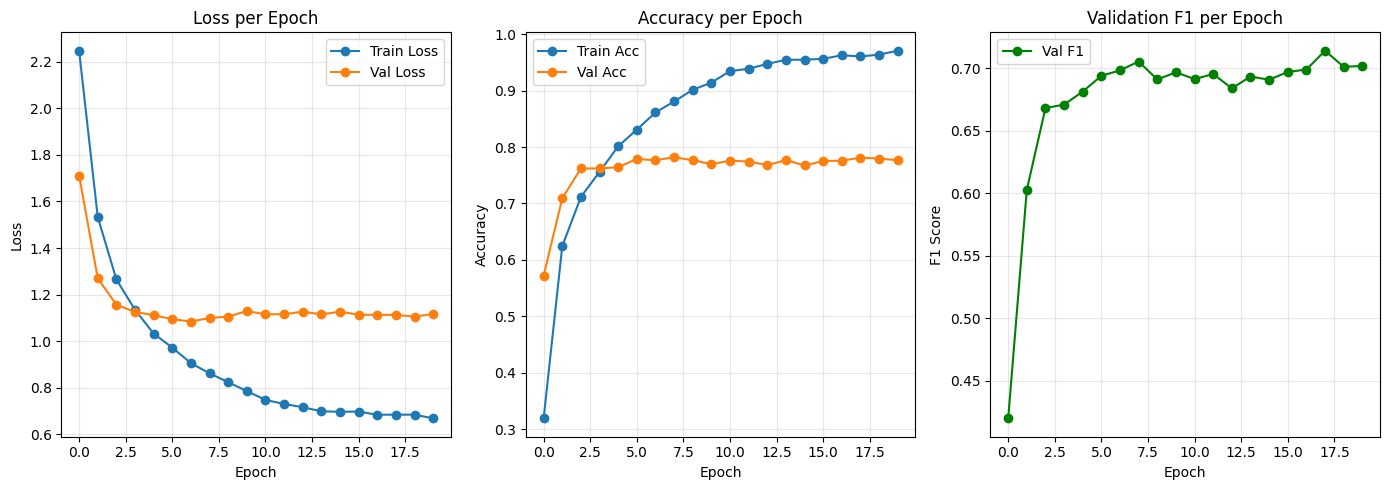

In [23]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.plot(history['train_loss'], label='Train Loss', marker='o')
plt.plot(history['val_loss'], label='Val Loss', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss per Epoch')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(history['train_acc'], label='Train Acc', marker='o')
plt.plot(history['val_acc'], label='Val Acc', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy per Epoch')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(history['val_f1'], label='Val F1', marker='o', color='green')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.title('Validation F1 per Epoch')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
%load_ext tensorboard
%tensorboard --logdir {TrainingConfig.LOG_DIR}

<IPython.core.display.Javascript object>

In [25]:
def display_predictions(model, data_loader, class_to_idx, device, num_images=15):
    """
    Displays a grid of images with their predicted label vs true label.
    Correct predictions are shown in green, incorrect ones in red.
    """
    idx_to_class = {v: k for k, v in class_to_idx.items()}
    imagenet_mean = [0.485, 0.456, 0.406]
    imagenet_std  = [0.229, 0.224, 0.225]

    model.eval()

    images, labels = next(iter(data_loader))   # grab one batch
    images, labels = images.to(device), labels.to(device)

    with torch.no_grad():
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

    plt.rcParams["figure.figsize"] = (15, 9)
    plt.figure()

    for i in range(min(num_images, len(labels))):
        plt.subplot(3, 5, i + 1)

        img_tensor = denormalize(images[i].cpu(), imagenet_mean, imagenet_std).clamp(0, 1)
        img = TF.to_pil_image(img_tensor)

        pred_label = idx_to_class[preds[i].item()]
        true_label = idx_to_class[labels[i].item()]

        color = "green" if pred_label == true_label else "red"

        plt.imshow(img)
        plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color, fontsize=10)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

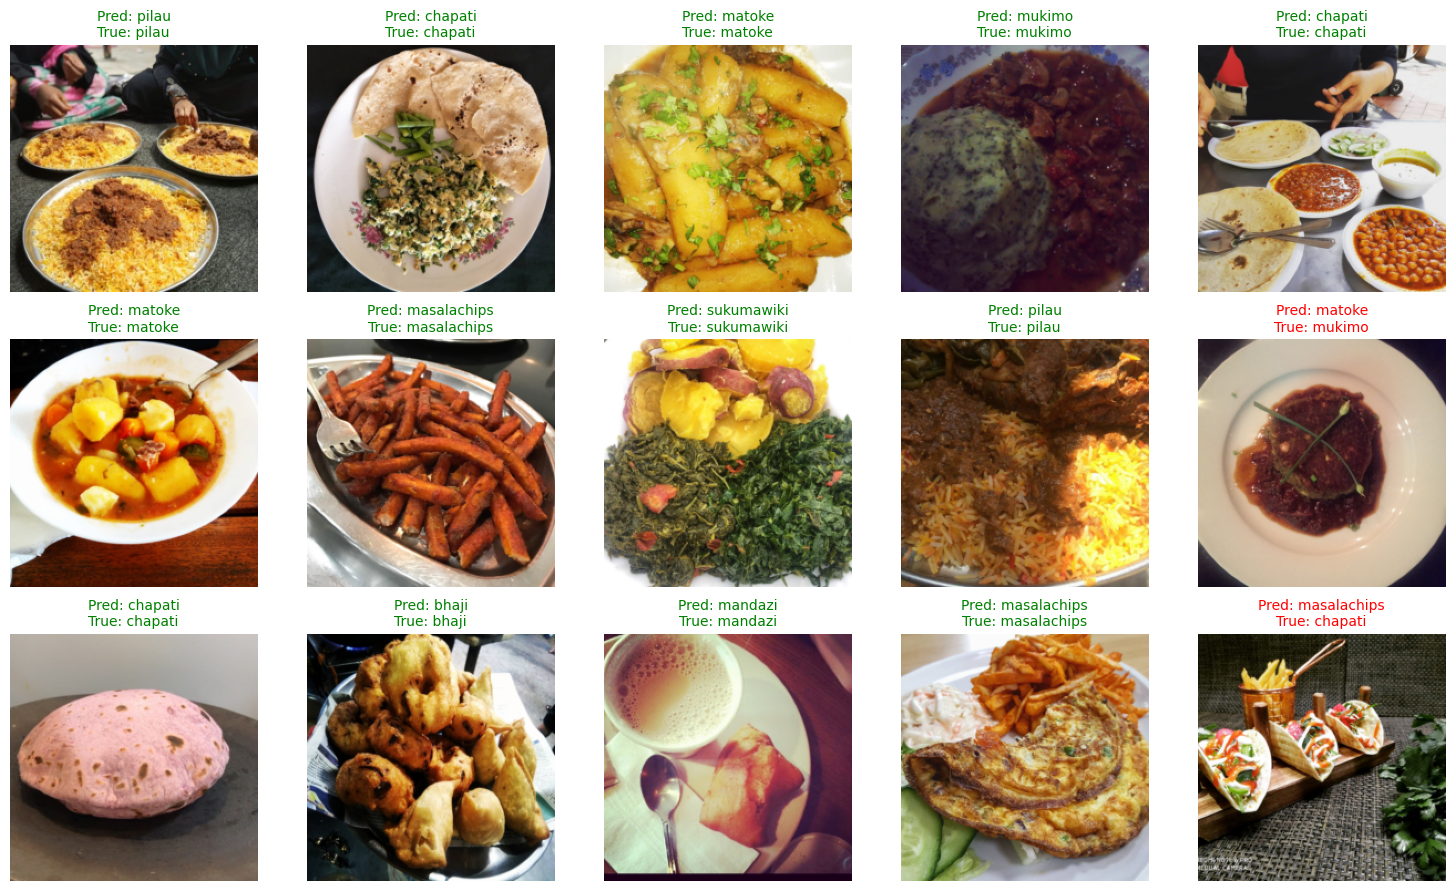

In [26]:
display_predictions(model, val_loader, class_to_idx, device, num_images=15)

In [27]:
class KenyanFood13TestDataset(Dataset):
    """
    Dataset for the unlabeled test set - only images, no class labels.
    """

    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_id = str(self.df.loc[idx, 'id'])
        image = Image.open(os.path.join(self.img_dir, f"{img_id}.jpg")).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, img_id   # return the id instead of a label


In [28]:
test_transform = transforms.Compose([
    transforms.Resize((DatasetConfig.IMG_HEIGHT, DatasetConfig.IMG_WIDTH)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

test_df = pd.read_csv(os.path.join(DatasetConfig.DATA_ROOT, 'test.csv'))

test_dataset = KenyanFood13TestDataset(test_df, img_dir, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=DatasetConfig.BATCH_SIZE, shuffle=False, num_workers=DatasetConfig.NUM_WORKERS)

print(f"Test samples: {len(test_dataset)}")

Test samples: 1638


In [29]:
idx_to_class = {v: k for k, v in class_to_idx.items()}

model.eval()

all_ids = []
all_preds = []

with torch.no_grad():
    for images, img_ids in test_loader:
        images = images.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        preds = preds.cpu().numpy()
        pred_labels = [idx_to_class[p] for p in preds]

        all_ids.extend(img_ids)
        all_preds.extend(pred_labels)

print(f"Total predictions: {len(all_preds)}")

Total predictions: 1638


In [30]:
sample_sub = pd.read_csv(os.path.join(DatasetConfig.DATA_ROOT, 'sample_submission.csv'))
print(sample_sub.head())
print(sample_sub.columns.tolist())

                    id        class
0  9156739011499789258        pilau
1  2049465964503133373   nyamachoma
2  6446998501027132988  masalachips
3  4194396063119815321   nyamachoma
4  9018117998187006009      mandazi
['id', 'class']


In [31]:
submission_df = pd.DataFrame({
    'id': all_ids,
    'class': all_preds
})

submission_df.to_csv('submission.csv', index=False)
print(submission_df.head())
print(f"Saved {len(submission_df)} predictions to submission.csv")

                    id       class
0  9156739011499789258  nyamachoma
1  2049465964503133373  kachumbari
2  6446998501027132988  nyamachoma
3  4194396063119815321       ugali
4  9018117998187006009     mandazi
Saved 1638 predictions to submission.csv
